# Ray Data: shuffle, repartition and sort

A seeded random_shuffle, a repartition into four blocks and a descending sort, then take(5).

**When to use it.** Randomizing training order, controlling parallelism and file counts, or producing ordered output.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

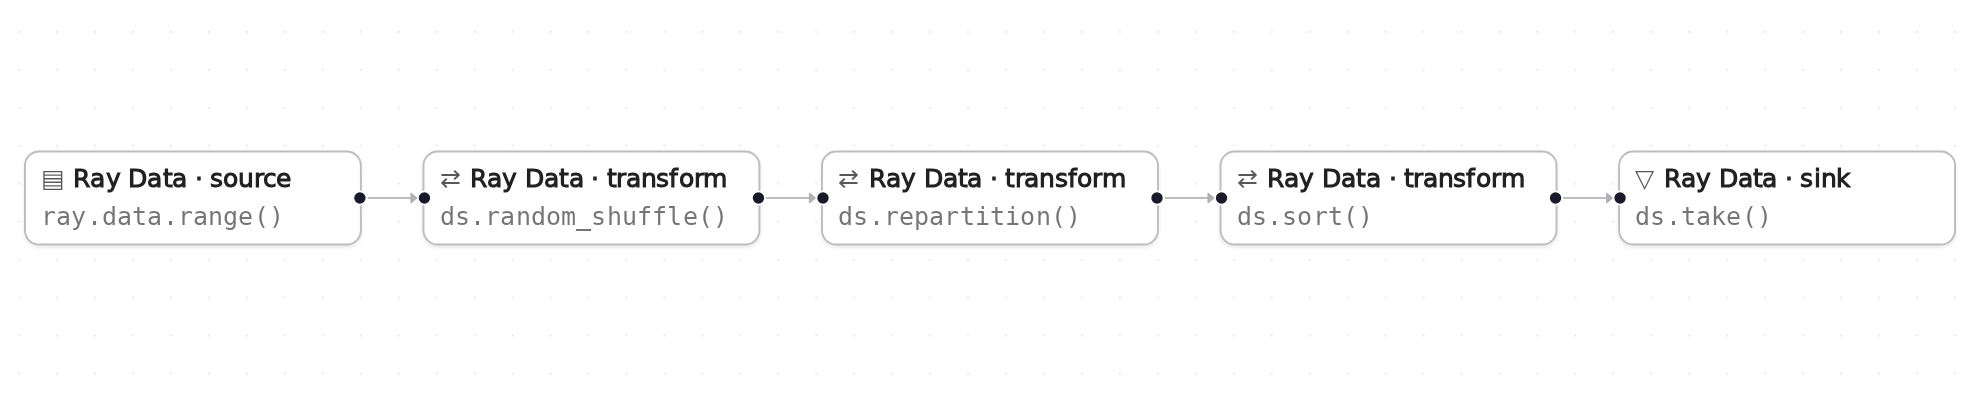

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(50)
ds = ds.random_shuffle(seed=42)
ds = ds.repartition(4)
ds = ds.sort("id", descending=True)
top5 = ds.take(5)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
assert [r["id"] for r in top5] == [49, 48, 47, 46, 45], top5
print(top5)

[{'id': 49}, {'id': 48}, {'id': 47}, {'id': 46}, {'id': 45}]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 8)

```python
ds = ray.data.range(50)
```

Fifty rows.

**Transform** (node `n2`, line 9)

```python
ds = ds.random_shuffle(seed=42)
```

random_shuffle(seed=42) is a full, reproducible row shuffle.

**Transform** (node `n3`, line 10)

```python
ds = ds.repartition(4)
```

repartition(4) rewrites the data into four blocks.

**Transform** (node `n4`, line 11)

```python
ds = ds.sort("id", descending=True)
```

sort("id", descending=True) orders the rows globally.

**Sink** (node `n5`, line 12)

```python
top5 = ds.take(5)
```

take(5) returns the five largest ids.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()